In [1]:
pip install split-folders

In [ ]:
pip install keras-tuner

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dense, Flatten, BatchNormalization, Conv2D, MaxPooling2D, Dropout

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras.preprocessing.image import ImageDataGenerator
#from sklearn.metrics import confusion_matrix
import itertools
import os
import shutil
import random
import glob
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category = FutureWarning )
%matplotlib inline
#import tensorflow_addons as tfa
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
#from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
#from sklearn.preprocessing import LabelBinarizer

In [ ]:
# Split your dataset using splitfolders
import splitfolders
splitfolders.ratio("/content/drive/MyDrive/MILK10k_Training_Input", output="Dataset12",
    seed=1337, ratio=(.7, .1, .2), group_prefix=None, move=False)  # def1ault values

splitfolders.fixed("/content/drive/MyDrive/MILK10k_Training_Input", output="Dataset12",
    seed=1337, fixed=(100, 100), oversample=False, group_prefix=None, move=False) # default values'''

In [ ]:
#assigning variables
train_path = '/content/Dataset12/train'
valid_path = '/content/Dataset12/val'
test_path = '/content/Dataset12/test'

In [ ]:
import os
from google.colab import drive

# Mount Google Drive
#drive.mount('/content/drive')
import os
from google.colab import drive

# Mount Google Drive
#drive.mount('/content/drive')

# Path to your dataset directory in Google Drive
data_dir = '/content/drive/MyDrive/color_5500/color_5500'  # Update as needed

# Get list of class names (folder names)
class_names = sorted([folder for folder in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, folder))])

# Print as comma-separated string
# Print class names in 'class1','class2','class3' format
print(",".join([f"'{cls}'" for cls in class_names]))


# Path to your dataset directory in Google Drive
data_dir = '/content/drive/MyDrive/color_5500/color_5500'  # change if your path is different

# Get list of class names (folders inside the dataset directory)
class_names = sorted([folder for folder in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, folder))])

# Print the class names
print("List of classes:")
for i, class_name in enumerate(class_names):
    print(f"{i}: {class_name}")


'AKIEC','BCC','BEN_OTH','BF','BKL','INF','MAL_OTH','MEL','NV','SCCKA','VASC'
List of classes:
0: AKIEC
1: BCC
2: BEN_OTH
3: BF
4: BKL
5: INF
6: MAL_OTH
7: MEL
8: NV
9: SCCKA
10: VASC


In [ ]:
train_batches = ImageDataGenerator(preprocessing_function=tf.keras.applications.vgg16.preprocess_input) \
    .flow_from_directory(directory=train_path, target_size=(224, 224), classes=['AKIEC','BCC','BEN_OTH','BF','BKL','INF','MAL_OTH','MEL','NV','SCCKA','VASC'], batch_size=32)
valid_batches = ImageDataGenerator(preprocessing_function=tf.keras.applications.vgg16.preprocess_input) \
    .flow_from_directory(directory=valid_path, target_size=(224, 224), classes=['AKIEC','BCC','BEN_OTH','BF','BKL','INF','MAL_OTH','MEL','NV','SCCKA','VASC'], batch_size=32)
test_batches = ImageDataGenerator(preprocessing_function=tf.keras.applications.vgg16.preprocess_input) \
    .flow_from_directory(directory=test_path, target_size=(224, 224), classes=['AKIEC','BCC','BEN_OTH','BF','BKL','INF','MAL_OTH','MEL','NV','SCCKA','VASC'], batch_size=32, shuffle=True)

Found 3892 images belonging to 11 classes.
Found 1100 images belonging to 11 classes.
Found 1112 images belonging to 11 classes.


In [ ]:
EPOCHS = 30
assert train_batches.n == 3892
assert valid_batches.n == 1100
assert test_batches.n == 1112
assert train_batches.num_classes == valid_batches.num_classes == test_batches.num_classes == 11

In [ ]:
imgs, labels = next(train_batches)

In [ ]:
#  this function will plot images of a grid with 1 row and 10 columns
def plotImages(images_arr):
    fig, axes = plt.subplots(1,10, figsize = (20,20))
    axes = axes.flatten()
    for img, ax in zip(images_arr, axes):
        ax.imshow(img)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
def residual_block(x, filters):
    shortcut = layers.Conv2D(filters, 1, padding='same')(x)

    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)

    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)
    return x


In [ ]:
def cnn_to_transformer(x, embed_dim=256):
    h, w, c = x.shape[1:]
    x = layers.Conv2D(embed_dim, 1)(x)
    x = layers.Reshape((h * w, embed_dim))(x)
    return x, h, w


In [ ]:
def transformer_block(x, num_heads=8, embed_dim=256, mlp_dim=512, dropout=0.1):

    attn = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim
    )(x, x)

    x = layers.Add()([x, attn])
    x = layers.LayerNormalization()(x)

    mlp = layers.Dense(mlp_dim, activation='gelu')(x)
    mlp = layers.Dense(embed_dim)(mlp)

    x = layers.Add()([x, mlp])
    x = layers.LayerNormalization()(x)
    return x


In [ ]:
from tensorflow.keras import layers, models

def build_mt_ra_tunet_cls(input_shape=(224,224,3), classes=11):

    inputs = layers.Input(input_shape)

    # ===== Encoder =====
    f1 = residual_block(inputs, 64)
    p1 = layers.MaxPooling2D()(f1)

    f2 = residual_block(p1, 128)
    p2 = layers.MaxPooling2D()(f2)

    f3 = residual_block(p2, 256)
    p3 = layers.MaxPooling2D()(f3)

    f4 = residual_block(p3, 512)

    # ===== Transformer Bottleneck =====
    tokens, h, w = cnn_to_transformer(f4, embed_dim=256)

    for _ in range(4):
        tokens = transformer_block(tokens)

    x = layers.Reshape((h, w, 256))(tokens)

    # ===== Decoder =====
    x = layers.Conv2DTranspose(256, 3, strides=2, padding='same')(x)
    x = layers.Concatenate()([x, f3])

    x = layers.Conv2DTranspose(128, 3, strides=2, padding='same')(x)
    x = layers.Concatenate()([x, f2])

    x = layers.Conv2DTranspose(64, 3, strides=2, padding='same')(x)
    x = layers.Concatenate()([x, f1])

    # ===== Classification Head =====
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(classes, activation='softmax')(x)

    return models.Model(inputs, outputs, name="MT_RA_TUNet_CLS")
import tensorflow as tf
from tensorflow.keras.utils import plot_model

# ============================
# Build Model
# ============================
model = build_mt_ra_tunet_cls(
    input_shape=(224, 224, 3),
    classes=11
)

# ============================
# 1. Print Model Summary
# ============================
model.summary()

# ============================
# 2. Plot Model Diagram
# ============================
plot_model(
    model,
    to_file="MT_RA_TUNet_CLS.png",   # saved image
    show_shapes=True,               # show tensor shapes
    show_layer_names=True,
    expand_nested=True,             # important for transformer blocks
    dpi=200
)


Model: "MT_RA_TUNet_CLS"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 224, 224,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 224, 224,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 224, 224,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 224, 224,  │     36,928 │ re_lu[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        256 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 224, 224,  │          0 │ add[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 112, 112,  │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 112, 112,  │    147,584 │ re_lu_2[0][0]     │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        512 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │      8,320 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 112, 112,  │          0 │ batch_normalizat

 Total params: 15,866,763 (60.53 MB)

 Trainable params: 15,862,923 (60.51 MB)

 Non-trainable params: 3,840 (15.00 KB)

In [ ]:
history = model.fit(x=train_batches,
                    validation_data=valid_batches,
                    epochs=30,
                    #callbacks=[early_stopping, cehckpoint],
                    verbose=1)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 118s 3s/step - acc: 0.6440 - auc: 0.3510 - loss: 1.6324 - precision: 0.4429 - recall: 0.1601 - val_acc: 0.9543 - val_auc: 0.7440 - val_loss: 0.8222 - val_precision: 0.9638 - val_recall: 0.4260
Epoch 2/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - acc: 0.9072 - auc: 0.6736 - loss: 0.8793 - precision: 0.8085 - recall: 0.4841 - val_acc: 0.9857 - val_auc: 0.8840 - val_loss: 0.5280 - val_precision: 0.9658 - val_recall: 0.6780
Epoch 3/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - acc: 0.9615 - auc: 0.7848 - loss: 0.6035 - precision: 0.8624 - recall: 0.6573 - val_acc: 0.9896 - val_auc: 0.9000 - val_loss: 0.4060 - val_precision: 0.9372 - val_recall: 0.8060
Epoch 4/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - acc: 0.9723 - auc: 0.8173 - loss: 0.5002 - precision: 0.8799 - recall: 0.7459 - val_acc: 0.9947 - val_auc: 0.9320 - val_loss: 0.3231 - val_precision: 0.9711 - val_recall: 0.8740
Epoch 5/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - acc: 0.9836 - auc: 0.8569 -

In [ ]:
# Evaluate the model on the test dataset
# model.evaluate returns loss and all metrics specified in model.compile
loss, acc, auc, precision, recall = model.evaluate(test_batches, verbose=1)

print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {acc * 100:.2f}%")
print(f"Test AUC: {auc:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")

6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 394ms/step - acc: 0.9998 - auc: 0.9908 - loss: 0.0399 - precision: 0.9908 - recall: 0.9881
Test Loss: 0.0673
Test Accuracy: 98.33%
Test AUC: 0.9997
Test Precision: 0.9833
Test Recall: 0.9800


Model Training graphs \
*   Accuracy
*   Loss
*   AUC
*   Precision
*   Recall
*   F1-Score

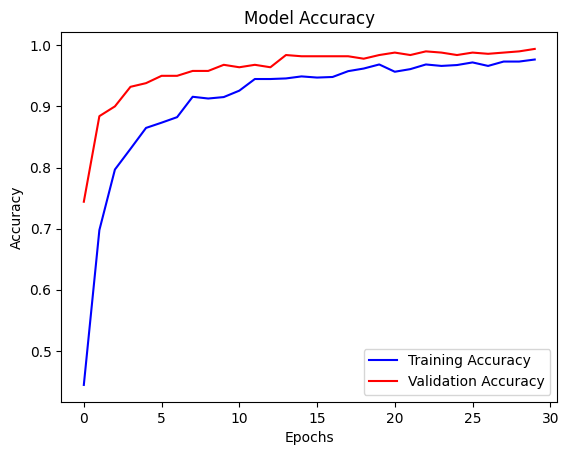

In [ ]:
plt.plot(history.history['auc'], 'b')
plt.plot(history.history['val_auc'], 'r')
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Training Accuracy", "Validation Accuracy"])
ax = plt.gca()
#ax.set_facecolor('gray')
#ax.grid(True, color='white')
plt.show()

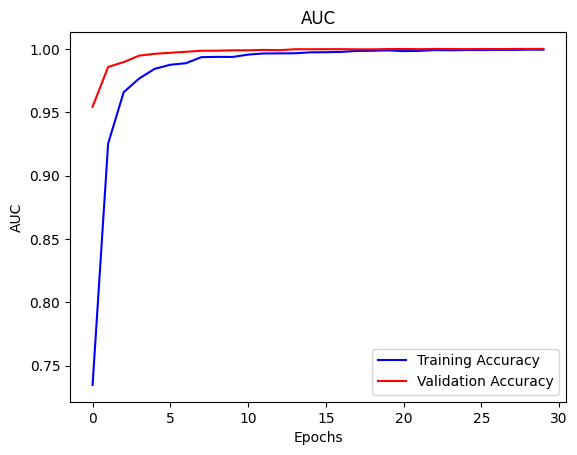

In [ ]:
plt.plot(history.history['acc'], 'b')
plt.plot(history.history['val_acc'], 'r')
plt.title("AUC")
plt.xlabel("Epochs")
plt.ylabel("AUC")
plt.legend(["Training Accuracy", "Validation Accuracy"])
ax = plt.gca()
#ax.set_facecolor('gray')
#ax.grid(True, color='white')
plt.show()

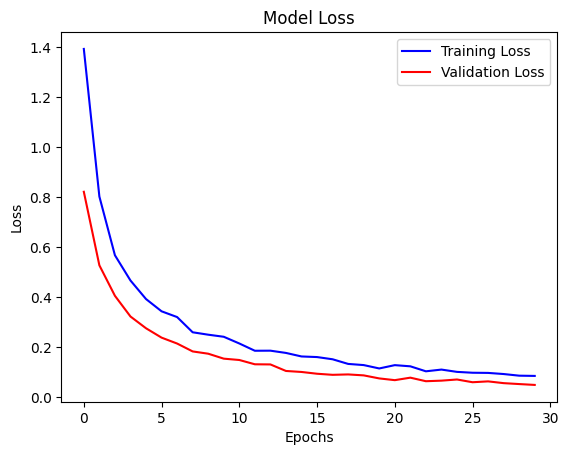

In [ ]:
import matplotlib.pyplot as plt

plt.figure(facecolor='white')  # Optional: overall figure background

plt.plot(history.history['loss'], 'b')
plt.plot(history.history['val_loss'], 'r')
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(["Training Loss", "Validation Loss"])

# Set the axes (plot area) background to light gray
#ax = plt.gca()
#ax.set_facecolor('gray')
#ax.grid(True, color='white')
plt.show()

In [ ]:
predictions = model.predict(x=test_batches, verbose=1)

6/6 ━━━━━━━━━━━━━━━━━━━━ 26s 419ms/step


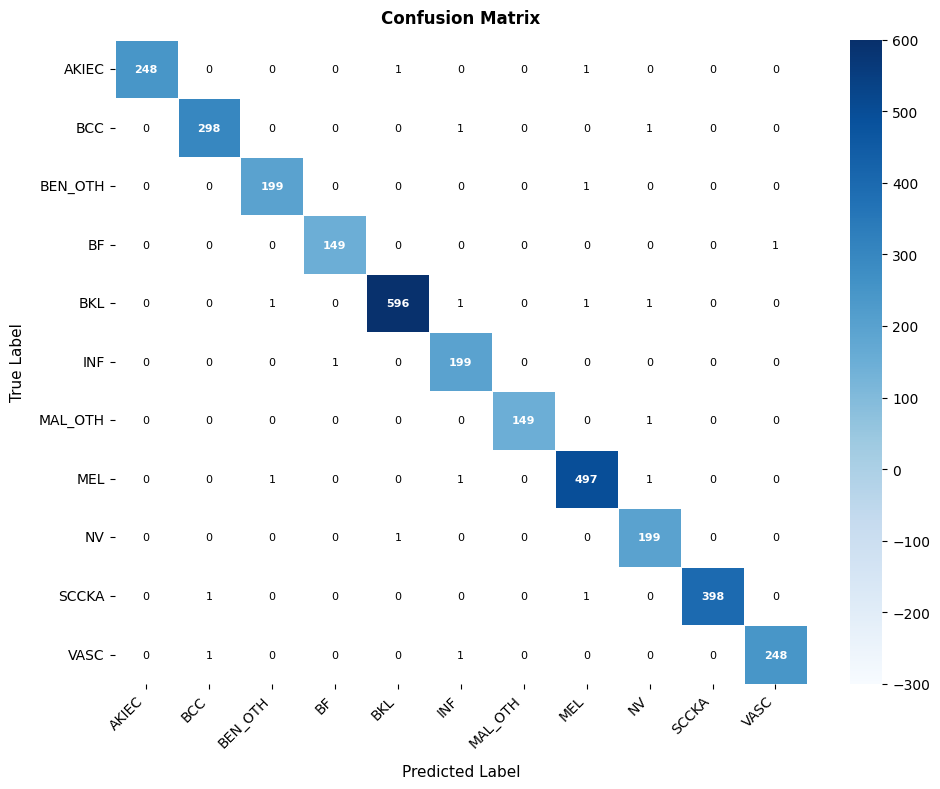

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import itertools
from sklearn.metrics import confusion_matrix

# ==========================
# CREATE CONFUSION MATRIX
# ==========================
cm = confusion_matrix(
    y_true=test_batches.classes,
    y_pred=np.argmax(predictions, axis=1)
)

# ==========================
# CLASS LABELS
# ==========================
cm_plot_labels = [
    'AKIEC','BCC','BEN_OTH','BF','BKL','INF','MAL_OTH','MEL','NV','SCCKA','VASC'
]

# ==========================
# PLOT FUNCTION
# ==========================
def plot_confusion_matrix(cm, classes, normalize=False,
                          title='Confusion Matrix',
                          cmap=plt.cm.Blues):

    plt.figure(figsize=(14, 12))

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized Confusion Matrix")
    else:
        print("Confusion Matrix (Counts)")

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title, fontsize=22, pad=20)
    plt.colorbar()

    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=30, ha='right', fontsize=14)
    plt.yticks(tick_marks, classes, fontsize=14)

    thresh = cm.max() / 2.0

    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        text_value = f"{cm[i, j]:.2f}" if normalize else f"{int(cm[i, j])}"
        plt.text(
            j, i, text_value,
            horizontalalignment="center",
            verticalalignment="center",
            fontsize=14,
            color="white" if cm[i, j] > thresh else "black"
        )

    plt.tight_layout()
    plt.ylabel('Actual Class', fontsize=16)
    plt.xlabel('Predicted Class', fontsize=16)
    plt.show()

# ==========================
# DISPLAY CONFUSION MATRIX
# ==========================
plot_confusion_matrix(
    cm=cm,
    classes=cm_plot_labels,
    normalize=False,   # set True for percentage view
    title='Confusion Matrix'
)

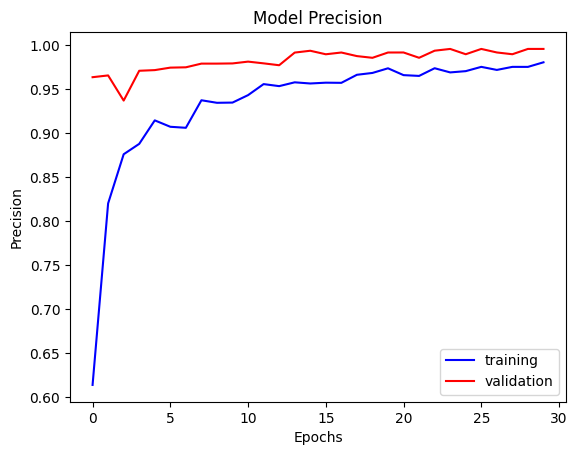

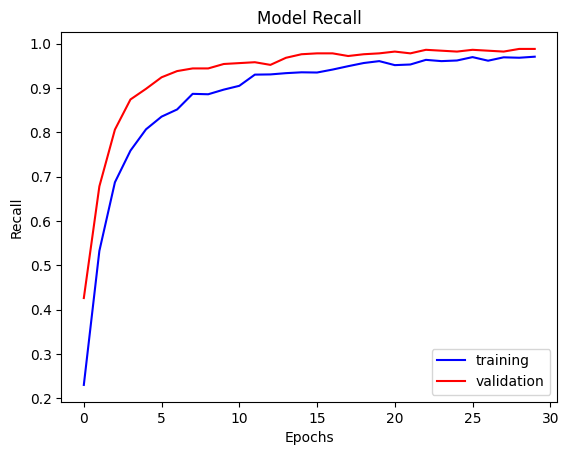

In [ ]:
plt.plot(history.history['precision'], 'b')
plt.plot(history.history['val_precision'], 'r')
plt.title("Model Precision")
plt.xlabel("Epochs")
plt.ylabel("Precision")
plt.legend(["training", "validation"])
ax = plt.gca()
#ax.set_facecolor('lightgray')
#ax.grid(True, color='white')
plt.show()

plt.plot(history.history['recall'], 'b')
plt.plot(history.history['val_recall'], 'r')
plt.title("Model Recall")
plt.xlabel("Epochs")
plt.ylabel("Recall")
plt.legend(["training", "validation"])
#ax = plt.gca()
#ax.set_facecolor('lightgray')
#ax.grid(True, color='white')
plt.show()

Classification Report

ROC Curve

4/4 ━━━━━━━━━━━━━━━━━━━━ 59s 9s/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step


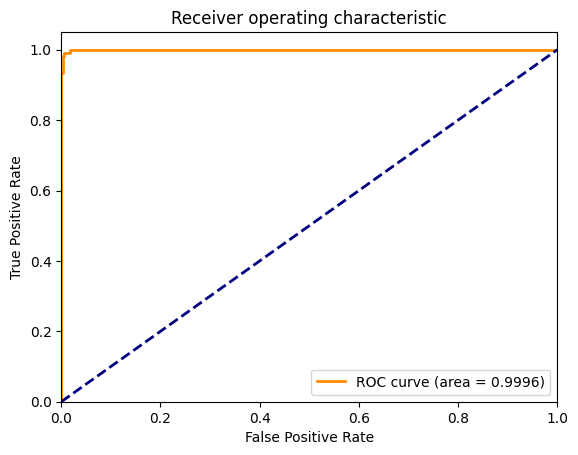

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Initialize empty lists to store true labels and predicted probabilities
true_labels = []
pred_probs = []

# Iterate over test batches to accumulate true labels and predicted probabilities
for i in range(len(test_batches)):
    batch_data, batch_labels = test_batches[i]
    true_labels.extend(batch_labels)
    pred_probs.extend(model.predict(batch_data))

# Convert lists to numpy arrays
true_labels = np.array(true_labels)
pred_probs = np.array(pred_probs)

# Ensure that the arrays are in the correct shape
if len(true_labels.shape) == 1:
    true_labels = true_labels.reshape(-1, 1)
if len(pred_probs.shape) == 1:
    pred_probs = pred_probs.reshape(-1, 1)

# Determine the number of classes
num_classes = true_labels.shape[1]

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(true_labels[:, i], pred_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(true_labels.ravel(), pred_probs.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Plot ROC curve for a specific class, e.g., class 2
plt.figure()
lw = 2
plt.plot(fpr[2], tpr[2], color="darkorange", lw=lw, label="ROC curve (area = %0.4f)" % roc_auc[2])
plt.plot([0, 1], [0, 1], color="navy", lw=lw, linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver operating characteristic")
plt.legend(loc="lower right")
plt.show()


Extension ROC Multiclass

/tmp/ipython-input-2517371719.py:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('tab20', n_classes)


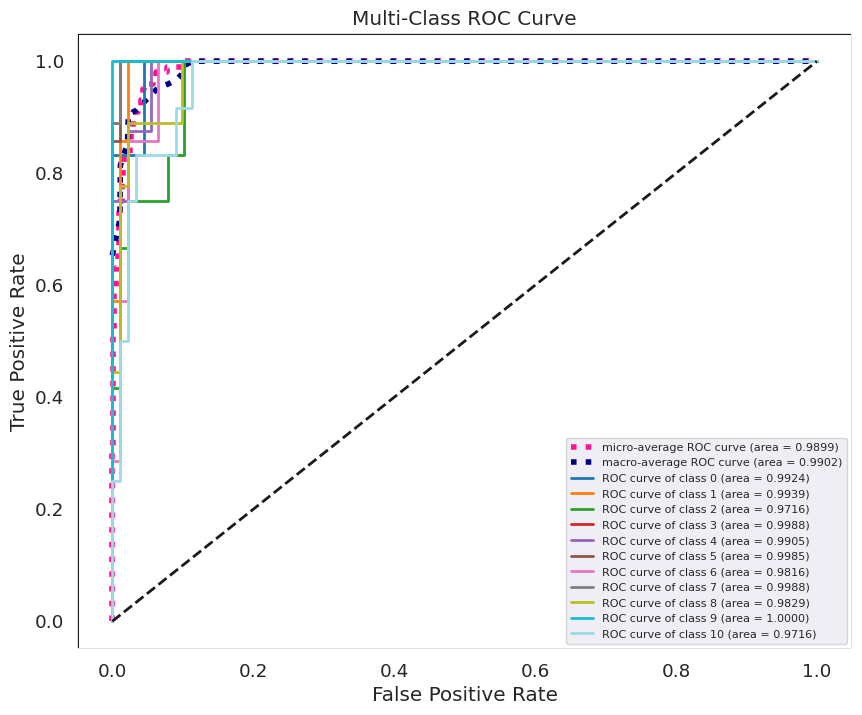

In [ ]:
import numpy as np

n_classes = 11
# First aggregate all false positive rates
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))

# Then interpolate all ROC curves at this points
mean_tpr = np.zeros_like(all_fpr)
for i in range(n_classes):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

# Finally average it and compute AUC
mean_tpr /= n_classes

fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot all ROC curves
plt.figure()
plt.plot(
    fpr["micro"],
    tpr["micro"],
    label="micro-average ROC curve (area = {0:0.4f})".format(roc_auc["micro"]),
    color="deeppink",
    linestyle=":",
    linewidth=4,
)

plt.plot(
    fpr["macro"],
    tpr["macro"],
    label="macro-average ROC curve (area = {0:0.4f})".format(roc_auc["macro"]),
    color="navy",
    linestyle=":",
    linewidth=4,
)

for i in range(n_classes):
    plt.plot(
        fpr[i],
        tpr[i],
        lw=lw,
        label="ROC curve of class {0} (area = {1:0.4f})".format(i, roc_auc[i]),
    )

plt.plot([0, 1], [0, 1], "k--", lw=lw)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-Class ROC Curve")
plt.legend(loc="lower right")
plt.show()